<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 30: Generative Model Output Comparison and Evaluation

Task 1: Generate 1,000 Samples from Each Model

Training epoch: 1
Training epoch: 2
Training epoch: 3
VAE: (1000, 28, 28, 1)
GAN: (1000, 28, 28, 1)


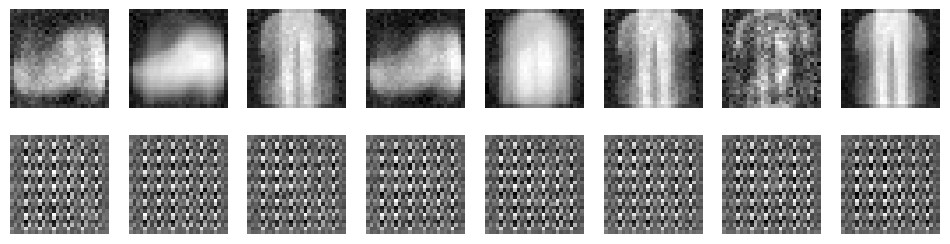

In [3]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model

tf.random.set_seed(42)
np.random.seed(42)

(x, _), _ = tf.keras.datasets.fashion_mnist.load_data()
x = x[:3000].astype('float32') / 255

# VAE encoder
inp = layers.Input((784,))
h = layers.Dense(128, activation='relu')(inp)
mu = layers.Dense(2)(h)
logvar = layers.Dense(2)(h)
encoder = Model(inp, [mu, logvar])

# VAE decoder
z_in = layers.Input((2,))
h = layers.Dense(128, activation='relu')(z_in)
out = layers.Dense(784, activation='sigmoid')(h)
decoder = Model(z_in, out)

opt = tf.keras.optimizers.Adam(0.001)
flat_x = x.reshape(-1, 784)

for epoch in range(3):
    for batch in tf.data.Dataset.from_tensor_slices(flat_x).batch(128):
        with tf.GradientTape() as tape:
            m, lv = encoder(batch)
            z = m + tf.exp(0.5 * lv) * tf.random.normal(tf.shape(m))
            recon = decoder(z)

            rec = tf.reduce_mean(tf.reduce_sum(
                tf.keras.backend.binary_crossentropy(batch, recon), axis=1))
            kl = -0.5 * tf.reduce_mean(tf.reduce_sum(
                1 + lv - tf.square(m) - tf.exp(lv), axis=1))
            loss = rec + kl

        weights = encoder.trainable_variables + decoder.trainable_variables
        opt.apply_gradients(zip(tape.gradient(loss, weights), weights))

# GAN generator
generator = tf.keras.Sequential([
    layers.Input((100,)),
    layers.Dense(7 * 7 * 128),
    layers.Reshape((7, 7, 128)),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(64, 4, strides=2, padding='same'),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(1, 4, strides=2,
                           padding='same', activation='tanh')
])

# GAN discriminator
discriminator = tf.keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(32, 4, strides=2, padding='same'),
    layers.LeakyReLU(),
    layers.Flatten(),
    layers.Dense(1)
])

g_opt = tf.keras.optimizers.Adam(0.0002)
d_opt = tf.keras.optimizers.Adam(0.0002)
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

data = tf.data.Dataset.from_tensor_slices(
    (x[..., None] * 2 - 1)
).shuffle(3000).batch(128)

for epoch in range(3):
    for real in data:
        noise = tf.random.normal((tf.shape(real)[0], 100))
        with tf.GradientTape() as gt, tf.GradientTape() as dt:
            fake = generator(noise, training=True)
            real_pred = discriminator(real, training=True)
            fake_pred = discriminator(fake, training=True)
            gl = bce(tf.ones_like(fake_pred), fake_pred)
            dl = (bce(tf.ones_like(real_pred), real_pred) +
                  bce(tf.zeros_like(fake_pred), fake_pred))

        g_opt.apply_gradients(zip(
            gt.gradient(gl, generator.trainable_variables),
            generator.trainable_variables))
        d_opt.apply_gradients(zip(
            dt.gradient(dl, discriminator.trainable_variables),
            discriminator.trainable_variables))

    print("Training epoch:", epoch + 1)

# Generate 1000 images
vae_images = decoder(
    np.random.randn(1000, 2).astype('float32'),
    training=False
).numpy().reshape(-1, 28, 28, 1)

gan_images = generator(
    tf.random.normal((1000, 100)),
    training=False
).numpy()
gan_images = np.clip((gan_images + 1) / 2, 0, 1)

print("VAE:", vae_images.shape)
print("GAN:", gan_images.shape)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(vae_images[i, :, :, 0], cmap='gray')
    axes[1, i].imshow(gan_images[i, :, :, 0], cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].axis('off')
plt.show()


Task 2: Calculate Inception Score and FID

In [4]:

from tensorflow.keras import layers, Model
from scipy.linalg import sqrtm

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

train_x = x_train[:10000].astype('float32') / 255
train_y = y_train[:10000]
real = x_test[:1000].astype('float32') / 255

train_x = train_x[..., None]
real = real[..., None]

inp = layers.Input((28, 28, 1))
h = layers.Flatten()(inp)
h = layers.Dense(128, activation='relu')(h)
features = layers.Dense(32, activation='relu')(h)
out = layers.Dense(10, activation='softmax')(features)

classifier = Model(inp, out)
feature_model = Model(inp, features)

classifier.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])
classifier.fit(train_x, train_y, epochs=3,
               batch_size=128, verbose=0)

def inception_score(images):
    p = classifier.predict(images, verbose=0)
    marginal = p.mean(axis=0)
    kl = np.sum(p * (np.log(p + 1e-10) -
                     np.log(marginal + 1e-10)), axis=1)
    return float(np.exp(kl.mean()))

def fid_score(real_features, fake_features):
    m1, m2 = real_features.mean(0), fake_features.mean(0)
    c1, c2 = np.cov(real_features, rowvar=False), np.cov(fake_features, rowvar=False)
    covmean = sqrtm(c1 @ c2)
    return float(np.sum((m1 - m2)**2) +
                 np.trace(c1 + c2 - 2 * np.real(covmean)))

real_f = feature_model.predict(real, verbose=0)
vae_f = feature_model.predict(vae_images, verbose=0)
gan_f = feature_model.predict(gan_images, verbose=0)

metrics = {
    'VAE': [inception_score(vae_images), fid_score(real_f, vae_f)],
    'GAN': [inception_score(gan_images), fid_score(real_f, gan_f)]
}

print(pd.DataFrame(metrics, index=['IS', 'FID']).round(3))


         VAE      GAN
IS     1.253    1.000
FID  191.858  315.729


/tmp/ipykernel_489/2473401629.py:38: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = sqrtm(c1 @ c2)


Task 3: Measure Diversity and Detect Mode Collapse

VAE Diversity: 0.333
GAN Diversity: -0.0


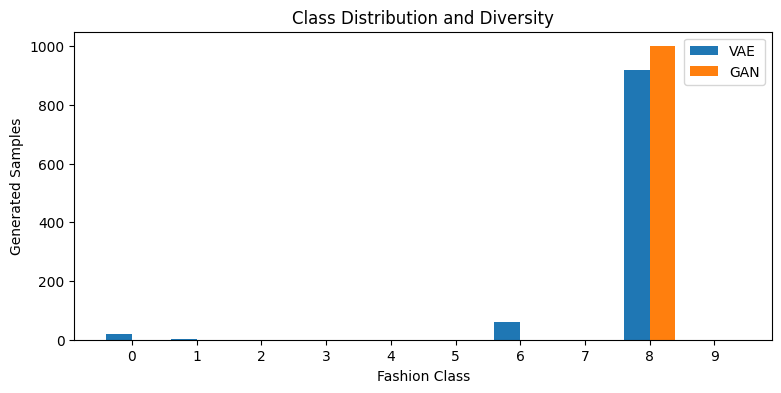

In [5]:

vae_labels = classifier.predict(
    vae_images, verbose=0
).argmax(axis=1)

gan_labels = classifier.predict(
    gan_images, verbose=0
).argmax(axis=1)

vae_counts = np.bincount(vae_labels, minlength=10)
gan_counts = np.bincount(gan_labels, minlength=10)

def diversity(counts):
    p = counts / counts.sum()
    return -np.sum(p * np.log(p + 1e-10))

print("VAE Diversity:", round(diversity(vae_counts), 3))
print("GAN Diversity:", round(diversity(gan_counts), 3))

plt.figure(figsize=(9, 4))
x = np.arange(10)
plt.bar(x - 0.2, vae_counts, width=0.4, label='VAE')
plt.bar(x + 0.2, gan_counts, width=0.4, label='GAN')
plt.xlabel('Fashion Class')
plt.ylabel('Generated Samples')
plt.title('Class Distribution and Diversity')
plt.xticks(x)
plt.legend()
plt.show()


Task 4: Compare Feature Distributions Using PCA

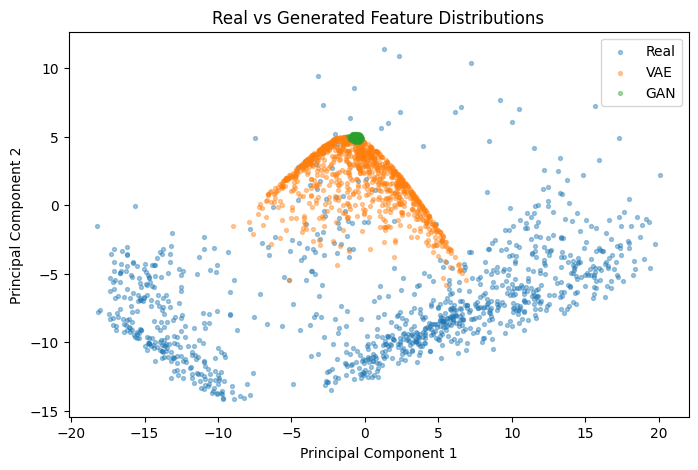

In [6]:

from sklearn.decomposition import PCA

combined = np.vstack([real_f, vae_f, gan_f])
reduced = PCA(n_components=2).fit_transform(combined)

plt.figure(figsize=(8, 5))

for i, name in enumerate(['Real', 'VAE', 'GAN']):
    points = reduced[i*1000:(i+1)*1000]
    plt.scatter(points[:, 0], points[:, 1],
                s=8, alpha=0.4, label=name)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Real vs Generated Feature Distributions')
plt.legend()
plt.show()


Task 5: Tabulate Metrics and Recommend a Model

In [7]:

summary = pd.DataFrame({
    'Model': ['VAE', 'GAN'],
    'Inception Score': [metrics['VAE'][0], metrics['GAN'][0]],
    'FID': [metrics['VAE'][1], metrics['GAN'][1]],
    'Diversity': [diversity(vae_counts), diversity(gan_counts)]
})

print(summary.round(3).to_string(index=False))

# Select using FID as the primary metric
best = summary.loc[summary['FID'].idxmin(), 'Model']

print("\nRecommended Model:", best)
print("Reason: Lower FID indicates closer similarity")
print("between generated and real image features.")


Model  Inception Score     FID  Diversity
  VAE            1.253 191.858      0.333
  GAN            1.000 315.729     -0.000

Recommended Model: VAE
Reason: Lower FID indicates closer similarity
between generated and real image features.
